In [ ]:
!pip install langgraph
!pip install langchain_groq
!pip install dotenv

In [24]:
from langgraph.graph import StateGraph, START,END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import  ChatOpenAI
from langchain_core.prompts import ChatMessagePromptTemplate
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [25]:
load_dotenv()

True

In [26]:
llm= ChatGroq(model="openai/gpt-oss-120b")


In [27]:
from langgraph.graph.message import add_messages
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage],add_messages]

In [28]:
def chat_node(state: ChatState):
 # take query from state
  messages = state['messages']
 #send to llm 
  response = llm.invoke(messages)
 # response store state
  return {'messages': [response]}  


In [29]:

checkpoint = MemorySaver()

graph= StateGraph(ChatState)
# Lets add nodes
graph.add_node('chat_node', chat_node)

# add edges

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node' ,END)


chatbot = graph.compile(checkpointer=checkpoint)

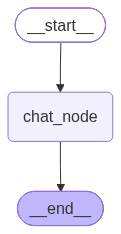

In [30]:
chatbot

In [ ]:
initial_message = {
    'messages' :[HumanMessage(content="What is object oriented programming in one line? ") ]
}

response = chatbot.invoke(initial_message)

In [ ]:
response['messages'][-1].content

'Object‑oriented programming is a paradigm that structures software as interacting “objects” that encapsulate data and behavior.'

In [34]:
thread_id = "1"


while True:
    user_message = input('Type here: ')
    print('User:' , user_message)

    if user_message.strip().lower() in ['exit', 'quit' , 'bye']:
        break

    config = {'configurale': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI:', response['messages'][-1].content)

User: hi


KeyError: 'thread_id'